In [1]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from plotting_utils import (
    get_train_domain,
    get_test_domain,
    get_model_name,
    wanted_metrics,
    load_config,
    load_generations
)

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.multi_sparse', True)
PROJECT_DIR = os.environ["MDS"]

%matplotlib notebook

In [2]:
wanted_metrics

['unieval_factuality',
 'prometheus_factuality',
 'prometheus_consistency',
 'unieval_relevance',
 'prometheus_relevance',
 'rouge_rouge1',
 'rouge_rougeLsum',
 'moverscore',
 'unieval_fluency',
 'prometheus_fluency',
 'unieval_coherence',
 'prometheus_coherence',
 'compression_sentence',
 'compression_token',
 'prometheus_coverage']

# Load and format results

In [3]:
experiments_config = load_config(f"{os.environ['MDS']}/code/experiments_mayarr.json")
experiment_results_folder = f"{os.environ['MDS']}/results_mayarr_sample"

In [4]:
df = []
split = "test"
for dataset in experiments_config["datasets"]:
    ground_truth_path = f"{os.environ['MDS']}/data/{dataset}/{split}.jsonl"
    if "sample" in experiment_results_folder:
        ground_truth_path = ground_truth_path.replace(f"{split}.jsonl", f"{split}.sample.jsonl")
    for model in experiments_config["models"]:
        # Prepare paths
        results_base = f"{experiment_results_folder}/{model}/{dataset}/{split}"
        generated_path = os.path.join(results_base, "generated.jsonl")
        results_path = os.path.join(results_base, "evaluation.json")
        
        if not os.path.exists(generated_path) or not os.path.exists(results_path):
            print(f"Skipping {dataset=} {model=} {split=}")
            continue
        
        # Load generations and ground truth
        try:
            temp = [e for e in load_generations(ground_truth_path, generated_path)]
        except Exception as err:
            print(f"Error loading. Skipping.\n{err=}")
            continue
        
        temp = pd.DataFrame(temp)
        temp["model"] = model
        temp["dataset"] = dataset
        temp["n_docs"] = temp.source.map(len)
        
        # Load results
        with open(results_path, "r") as f:
            results = json.load(f)
        
        for metric_name, metric_results in results.items():
            metric_results = metric_results.get("individual", [pd.NA] * len(temp))
            try:
                temp[metric_name] = metric_results
            except ValueError as err:
                print(f"{results_path=}\n{metric_name=}\n{err=}")
                continue
        
        df.append(temp)

# Cleanup
df = pd.concat(df).reset_index(drop=True)
df["train_domain"] = df.apply(get_train_domain, axis="columns")
df["test_domain"] = df.dataset.map(get_test_domain)
df["model_type"] = df.model.map(get_model_name)
df["is_domain_transfer"] = df.apply(lambda x: x.train_domain != x.test_domain, axis="columns")


def unroll_dict(row):
    new_cols = {}
    for metric in ["rouge", "unieval", "compression", "prometheus"]:
        if isinstance(row[metric], dict):
            for sub_metric, v in row[metric].items():
                new_cols[f"{metric}_{sub_metric}"] = v
    return new_cols

unrolled_cols = df.apply(func=unroll_dict, axis="columns", result_type="expand")
df = df.join(unrolled_cols)

# Save
output_file = f"{experiment_results_folder.split('/')[-1]}_all_df.pkl"
df.to_pickle(output_file)


In [5]:
# # Hack to replace prometheus values
# df_prom = pd.read_pickle("/home/adeluci2/projects/multidoc_summarization/notebooks/results_mayarr_sample_all_df.pkl")
# df_prom = df_prom.drop_duplicates(subset=["model", "dataset", "id"])
# prometheus_cols = [c for c in df_prom.columns if "prometheus_" in c]
# id_to_prom = df_prom.set_index(["model", "dataset", "id"])[prometheus_cols].to_dict(orient="index")

# df = pd.read_pickle("/home/adeluci2/projects/multidoc_summarization/notebooks/results_mayarr_all_df.pkl")
# df.loc[:, prometheus_cols] = np.nan

# def replace_prometheus_values(row, col):
#     return id_to_prom.get((row.model, row.dataset, row.id), {}).get(col, np.nan)

# for col in prometheus_cols:
#     df[col] = df.apply(lambda x: replace_prometheus_values(x, col), axis="columns")


In [6]:
df

,id,source,target,generated,prob,error,model,dataset,n_docs,compression,...,unieval_relevance,compression_sentence,compression_token,prometheus_coherence,prometheus_consistency,prometheus_coverage,prometheus_factuality,prometheus_fluency,prometheus_readability,prometheus_relevance
0,https://www.reddit.com/r/riseagainst/comments/...,[Title: Anyone else go to the show in Detroit ...,All of the commenters on this post share their...,All of the commenters on this post share their...,1.00,None,ground_truth,convosumm/reddit,14,"{'sentence': 0.13513513513513514, 'token': 0.1...",...,0.99,0.14,0.16,4.00,4.00,3.00,4.00,3.00,4.00,3.00
1,https://www.reddit.com/r/dutchposer/comments/2...,[Title: IT'S MY EFFING CAKE DAY! COME GIVE ME ...,Many commentators discuss the vanity of having...,Many commentators discuss the vanity of having...,1.00,None,ground_truth,convosumm/reddit,23,"{'sentence': 0.08888888888888889, 'token': 0.1...",...,0.99,0.09,0.19,4.00,3.00,3.00,3.00,4.00,4.00,4.00
2,https://www.reddit.com/r/buildapc/comments/zmb...,[Title: [Build Help] I need a decision now and...,"For building a pc, commenters suggest going fo...","For building a pc, commenters suggest going fo...",1.00,None,ground_truth,convosumm/reddit,12,"{'sentence': 0.043478260869565216, 'token': 0....",...,0.98,0.04,0.10,3.00,3.00,3.00,3.00,4.00,3.00,3.00
3,https://www.reddit.com/r/keto/comments/2w2qlv/...,[Title: BCAAs and IF Subreddit: keto So I've b...,All commenters advise what supplements you can...,All commenters advise what supplements you can...,1.00,None,ground_truth,convosumm/reddit,10,"{'sentence': 0.06451612903225806, 'token': 0.1...",...,0.99,0.06,0.14,3.00,3.00,3.00,3.00,3.00,4.00,4.00
4,https://www.reddit.com/r/bicycling/comments/qo...,[Title: Bike racks - what to look for? Subredd...,Most commenters talk about the best bike racks...,Most commenters talk about the best bike racks...,1.00,None,ground_truth,convosumm/reddit,13,"{'sentence': 0.058823529411764705, 'token': 0....",...,0.99,0.06,0.06,3.00,3.00,2.00,3.00,3.00,3.00,3.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4195,53603,"[Plenty of churches contain relics of saints, ...",Archaeologists in bulgaria think they've found...,"In a significant archaeological discovery, a l...",1.00,None,ICL-multinews_plus,multinews_plus,2,"{'sentence': 3.0, 'token': 3.125874125874126}",...,0.90,3.00,3.13,4.00,4.00,4.00,3.00,4.00,NaN,4.00
4196,53592,[Twelve hours after house majority leader eric...,Now that majority leader eric cantor is out of...,House Republicans are convening at 4 p.m. Wedn...,1.00,None,ICL-multinews_plus,multinews_plus,2,"{'sentence': 2.75, 'token': 2.4619565217391304}",...,0.93,2.75,2.46,4.00,4.00,3.00,3.00,4.00,NaN,4.00
4197,52601,[Ukraine withdrew troops from the embattled st...,A ceasefire in ukraine didn't stop fighting in...,Ukraine's withdrawal from the strategic railwa...,1.00,None,ICL-multinews_plus,multinews_plus,2,"{'sentence': 2.8333333333333335, 'token': 2.58...",...,0.95,2.83,2.58,4.00,4.00,3.00,4.00,4.00,NaN,4.00
4198,54183,[The council on islamic-american relations ann...,The owner of a gun store in florida who declar...,"A Florida gun shop, Florida Gun Supply, is fac...",1.00,None,ICL-multinews_plus,multinews_plus,3,"{'sentence': 3.8, 'token': 3.648}",...,0.91,3.80,3.65,4.00,3.00,3.00,2.00,4.00,NaN,3.00


# Trend in \# of Source Documents and Metrics

In [7]:
# xaxis = "n_docs"

# for metric in wanted_metrics:
#     g = sns.FacetGrid(df, col="model_type", hue="is_domain_transfer")
#     g.map(sns.scatterplot, xaxis, metric)
#     g.add_legend()


# Metric Correlations

In [8]:
correlation_metrics = sorted(wanted_metrics) + ["n_docs"]

<IPython.core.display.Javascript object>


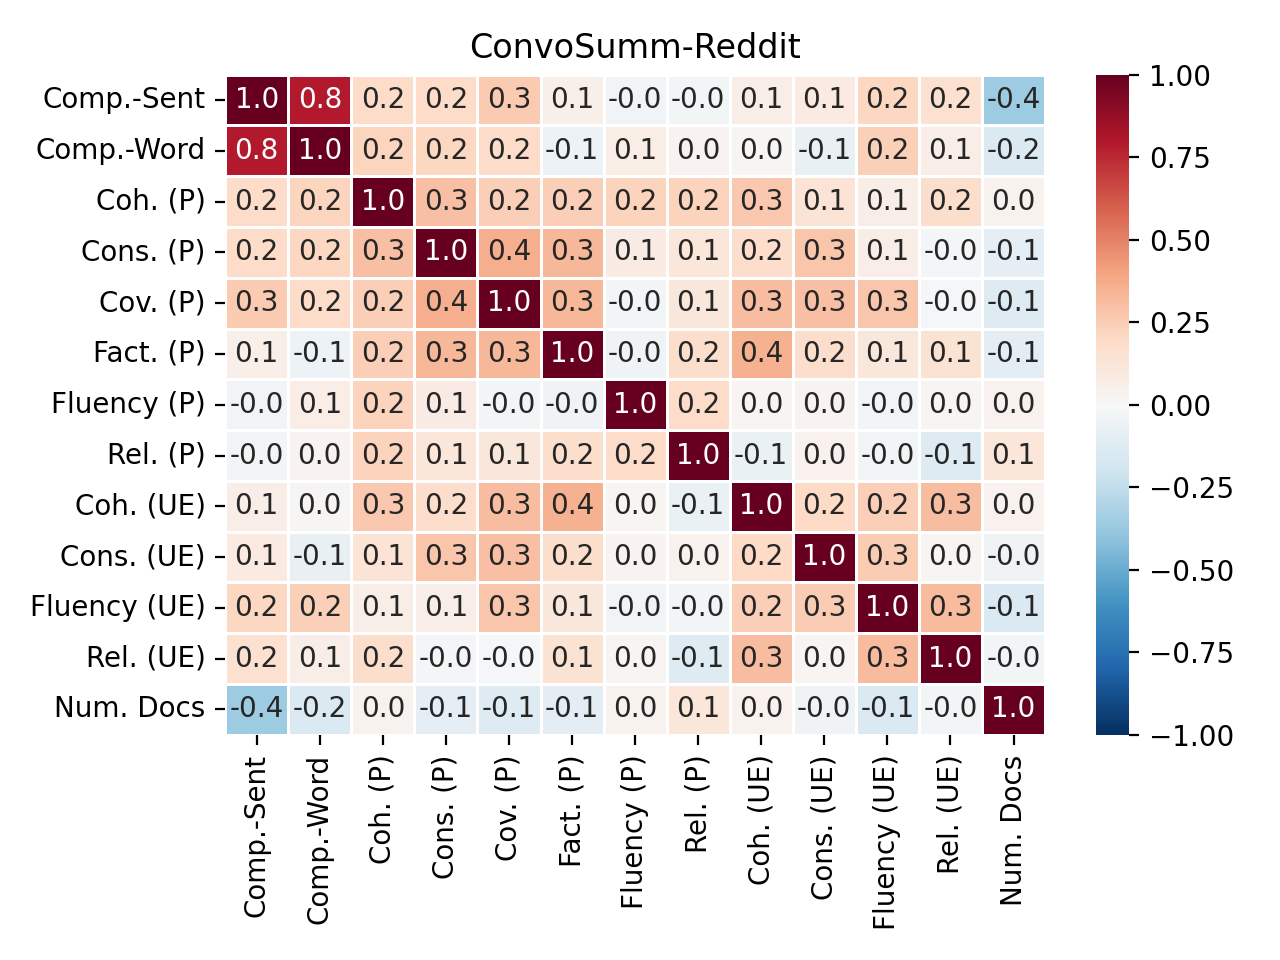

<IPython.core.display.Javascript object>


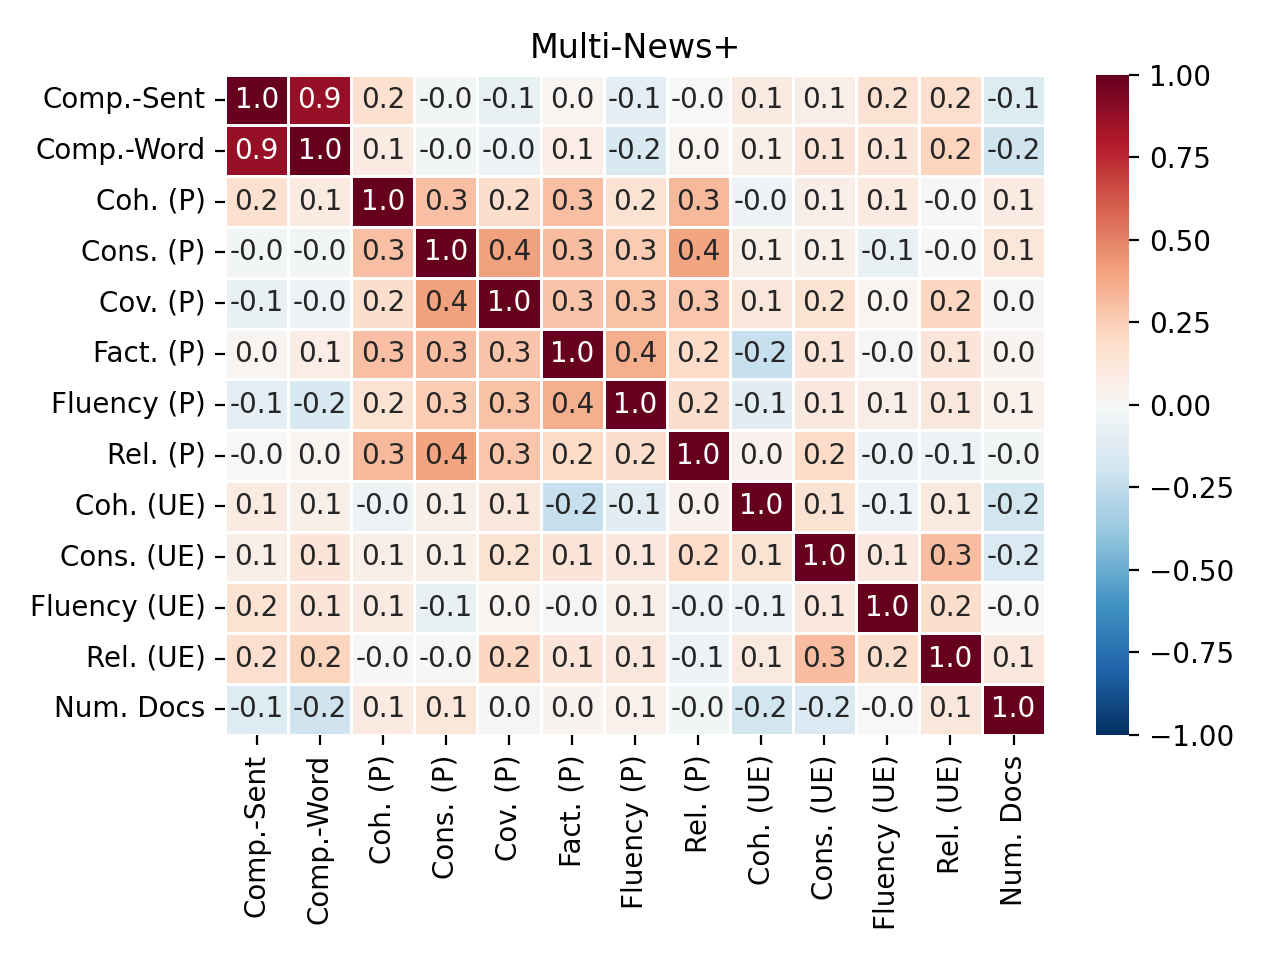

<IPython.core.display.Javascript object>


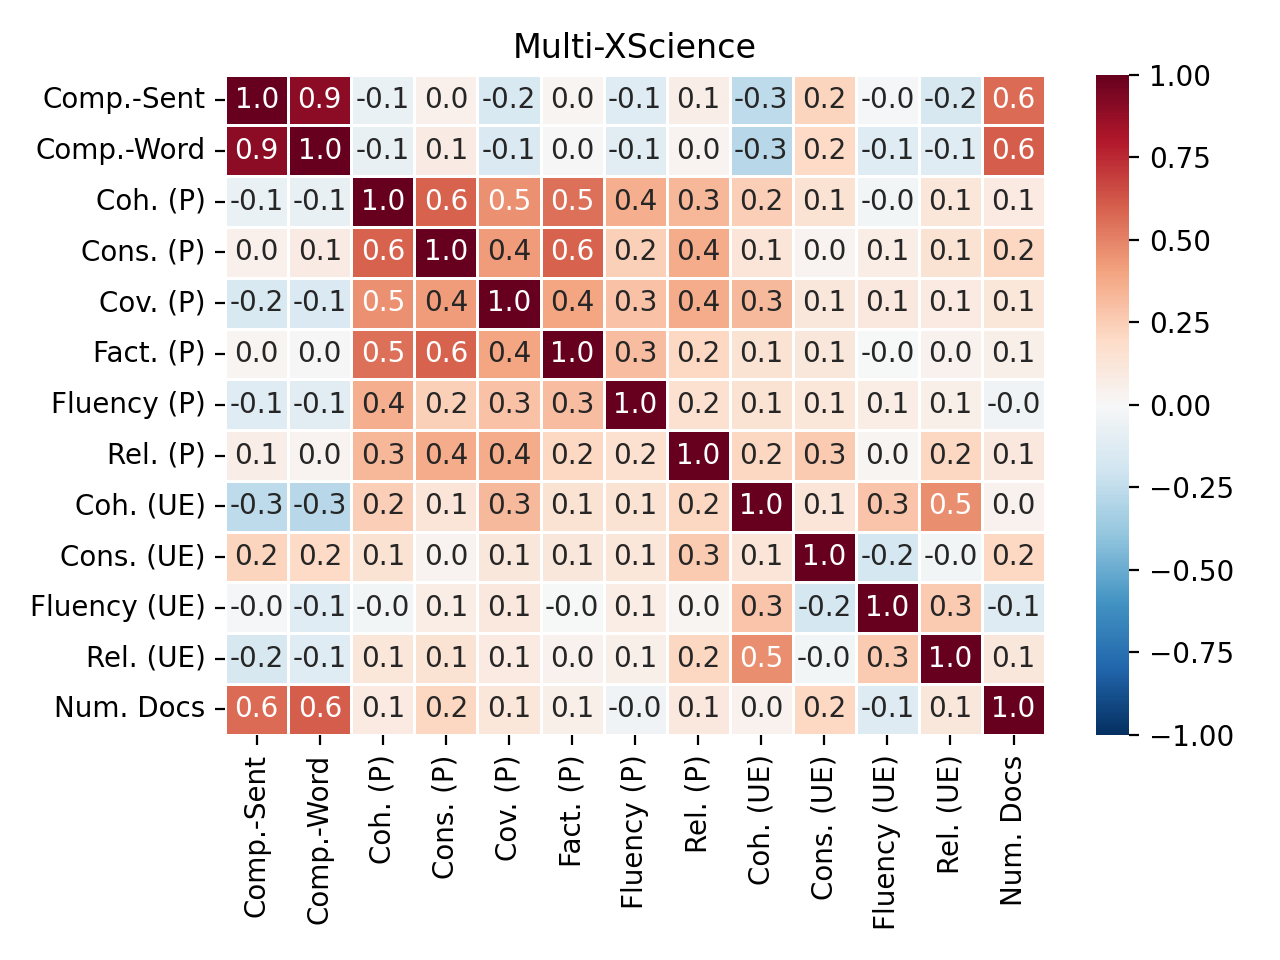

In [13]:
# Ground truth
# Drop the similarity metrics
new_cols = [c for c in correlation_metrics if c not in {"moverscore", "rouge_rouge1", "rouge_rougeLsum"}]

metric_name_mapping = {
    'unieval_factuality': 'Cons. (UE)',
    'prometheus_factuality': 'Fact. (P)',
    'prometheus_consistency': 'Cons. (P)',
    'unieval_relevance': 'Rel. (UE)',
    'prometheus_relevance': 'Rel. (P)',
    'rouge_rouge1': 'R1',
    'rouge_rougeLsum': 'RLSum',
    'moverscore': 'MoverScore',
    'unieval_fluency': 'Fluency (UE)', # Matches latest LaTeX table example
    'prometheus_fluency': 'Fluency (P)',
    'unieval_coherence': 'Coh. (UE)',
    'prometheus_coherence': 'Coh. (P)',
    'compression_sentence': 'Comp.-Sent',
    'compression_token': 'Comp.-Word', # Matches latest LaTeX table example
    'n_docs': 'Num. Docs',  # As seen in your example heatmap image
    "prometheus_coverage": "Cov. (P)"
    # Add any other column names from 'new_cols' that need to be mapped
}

run_to_title = {
    "Convo": "ConvoSumm-Reddit",
    "News+": "Multi-News+",
    "Science": "Multi-XScience"
}

counter = 1
for run, run_df in df[df.model_type=="ground_truth"].groupby("train_domain"):
    fig = plt.figure(num=counter)
    ax = plt.gca()
    ax.set_title(run_to_title[run])
    corr_df = run_df[new_cols].corr(method='pearson', min_periods=1, numeric_only=False)
    corr_df = corr_df.rename(columns=metric_name_mapping, index=metric_name_mapping)
    
    # Color pallettes: coolwarm, viridis
    sns.heatmap(corr_df, annot=True, fmt=".1f", linewidth=.5, cmap="RdBu_r", ax=ax, center=0.0, vmin=-1, vmax=1)
    counter += 1
    plt.tight_layout()



<IPython.core.display.Javascript object>


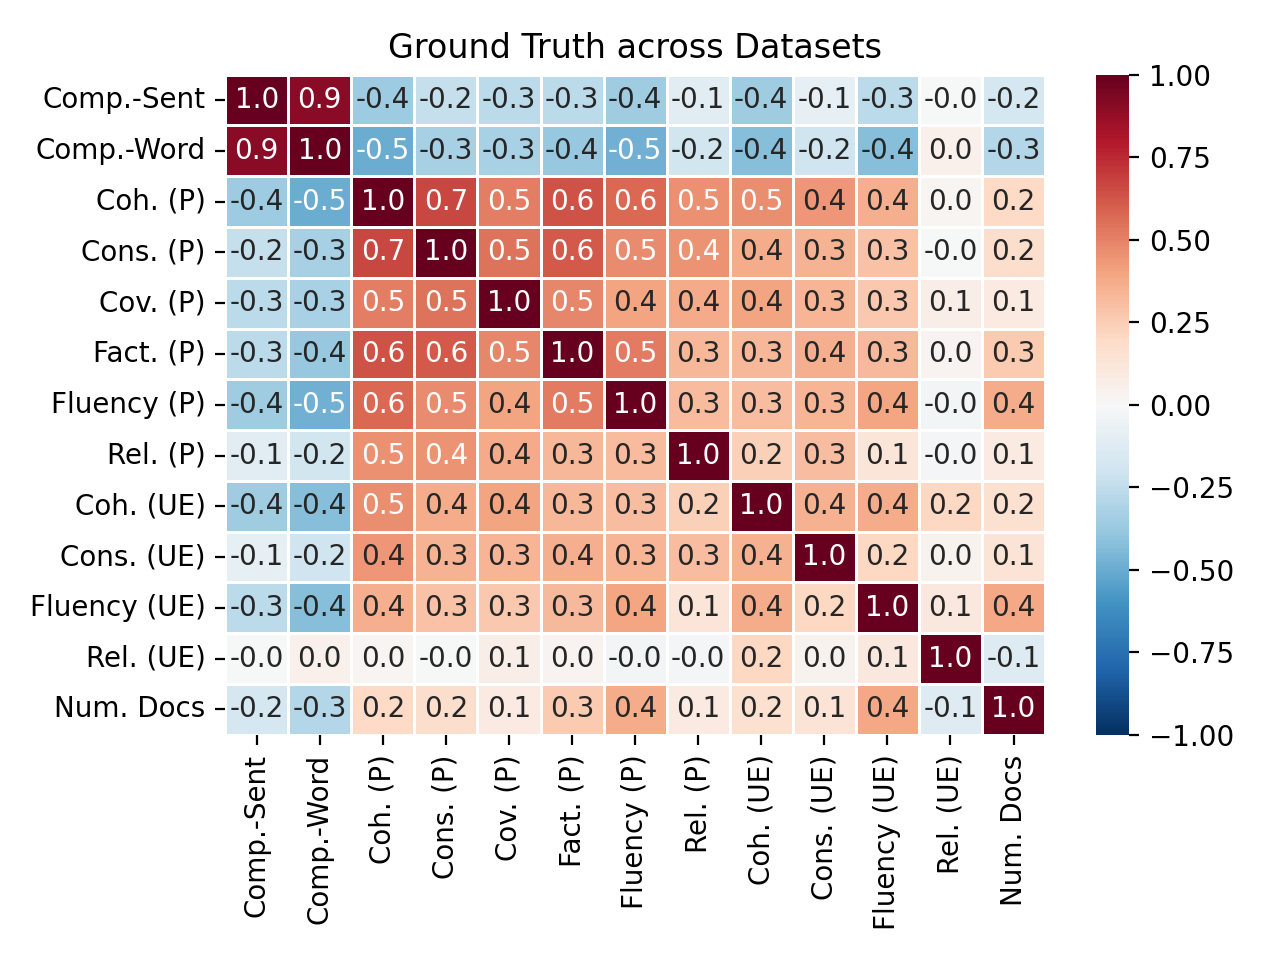

In [16]:
# Ground truth aggregated
fig = plt.figure(num=0)
ax = plt.gca()
ax.set_title("Ground Truth across Datasets")

corr_df = df[df.model_type=="ground_truth"][new_cols].corr(method='pearson', min_periods=1, numeric_only=False)
corr_df = corr_df.rename(columns=metric_name_mapping, index=metric_name_mapping)

# Color pallettes: coolwarm, viridis
sns.heatmap(corr_df, annot=True, fmt=".1f", linewidth=.5, cmap="RdBu_r", ax=ax, center=0.0, vmin=-1, vmax=1)
plt.tight_layout()



In [10]:
transfer_df = df[df.is_domain_transfer]

# def draw_heatmap(*args, **kwargs):
#     data = kwargs.pop('data')
#     d = data[correlation_metrics]
#     sns.heatmap(d, **kwargs)

# g = sns.FacetGrid(
#     data=df.groupby("train_domain")[correlation_metrics].corr(method='pearson', min_periods=1, numeric_only=False).reset_index(),
#     col="train_domain"
# )
# g.map_dataframe(draw_heatmap, annot=False, fmt=".1f", linewidth=.5, cmap="viridis")
# g.add_legend()

# counter = 1
# for run, run_df in transfer_df.groupby("train_domain"):
#     fig = plt.figure(num=counter)
#     ax = plt.gca()
#     ax.set_title(run)
#     corr_df = run_df[correlation_metrics].corr(method='pearson', min_periods=1, numeric_only=False)
#     sns.heatmap(corr_df, annot=False, fmt=".1f", linewidth=.5, cmap="viridis", ax=ax)
#     counter += 1


<IPython.core.display.Javascript object>


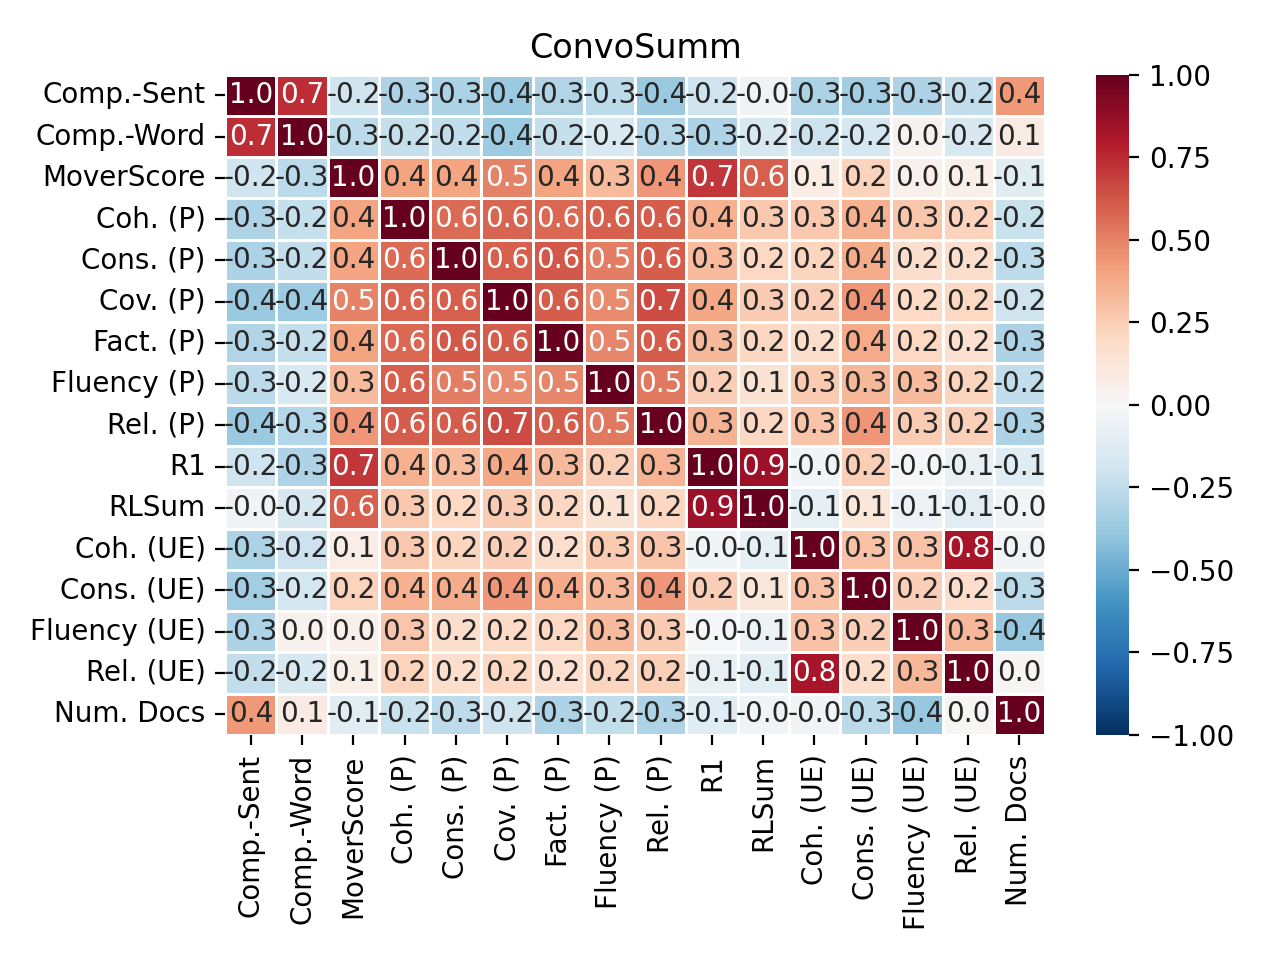

<IPython.core.display.Javascript object>


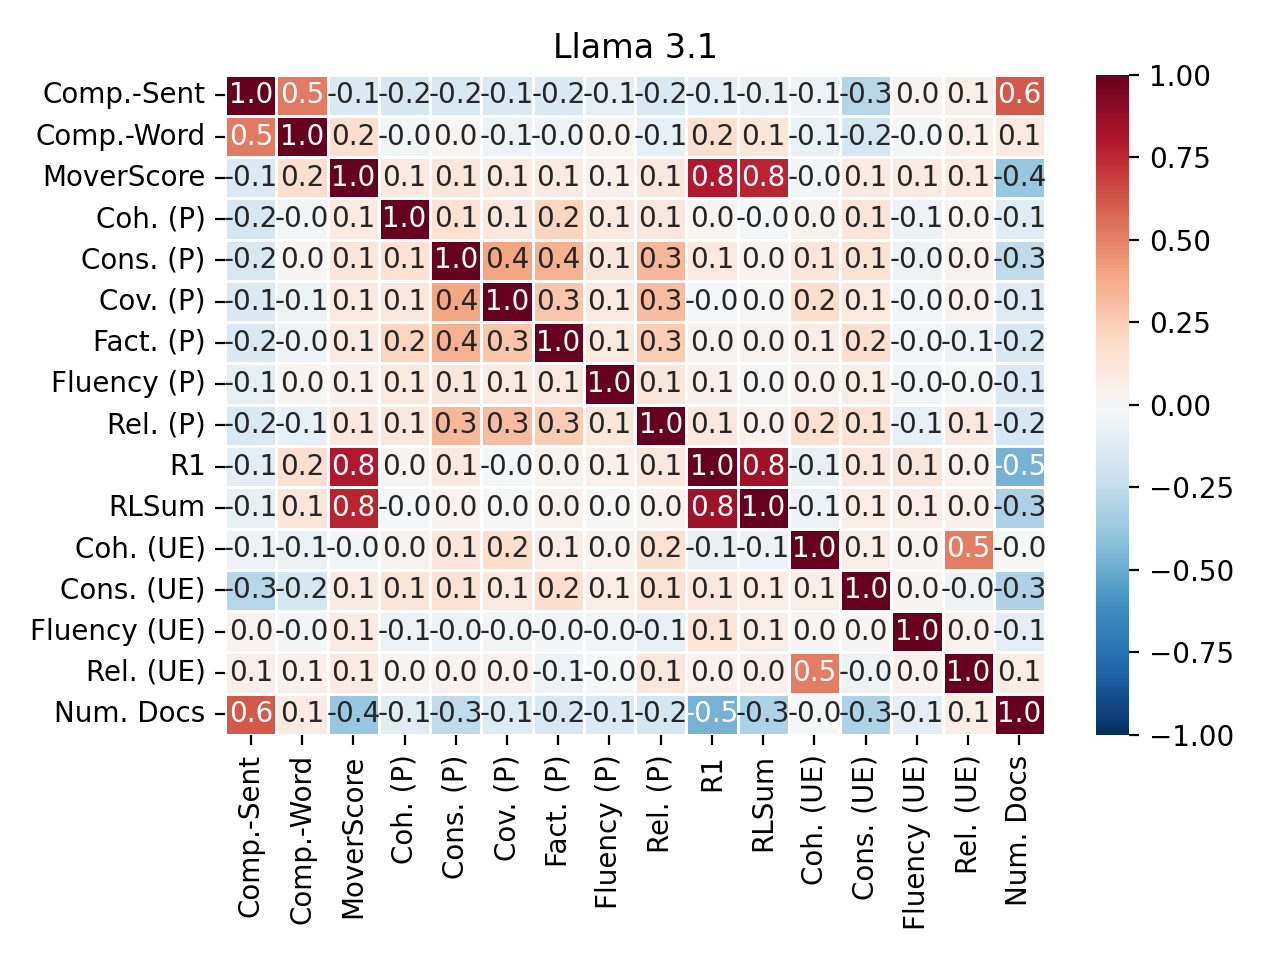

<IPython.core.display.Javascript object>


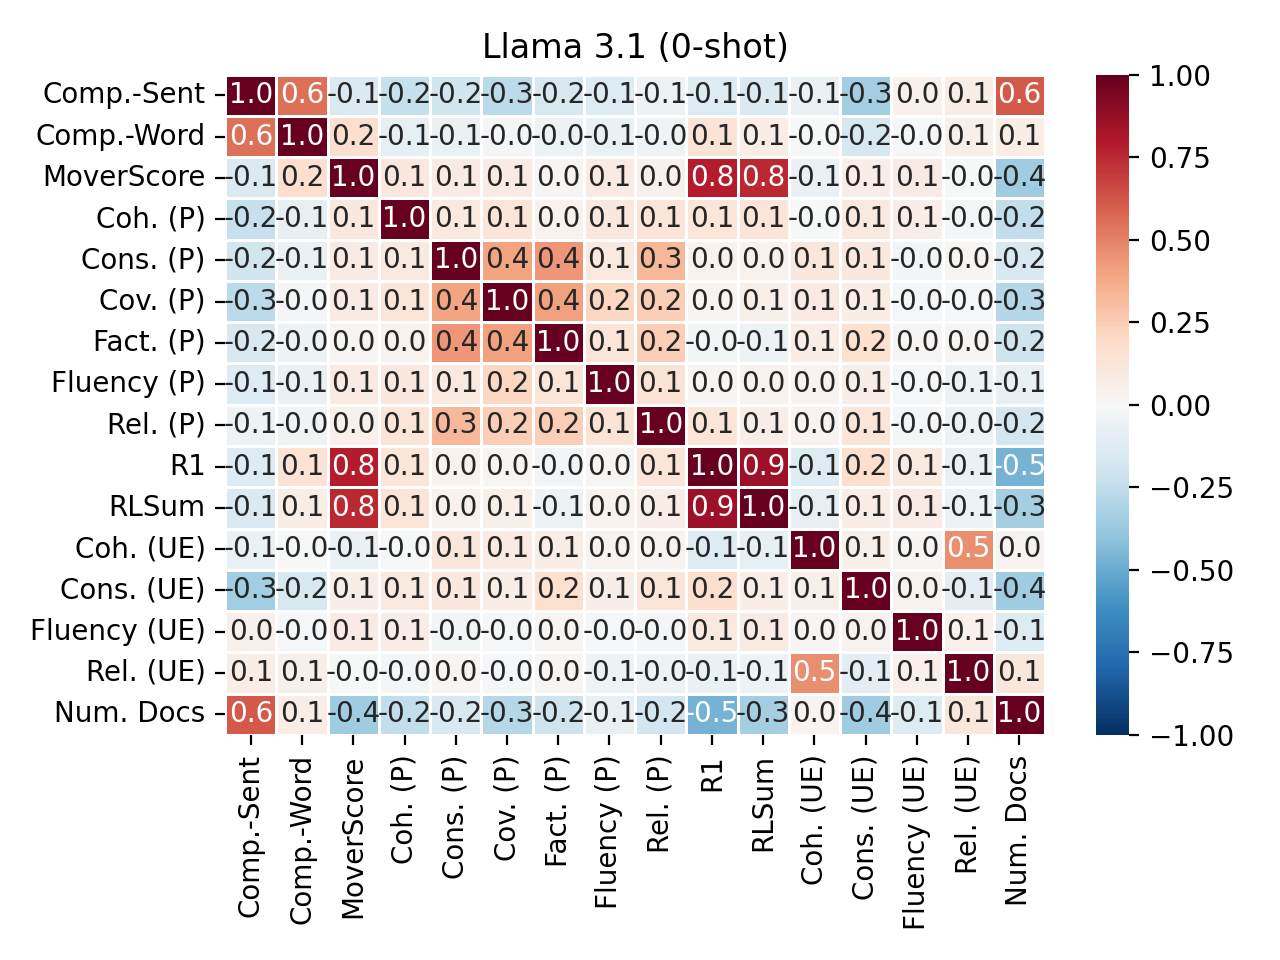

<IPython.core.display.Javascript object>


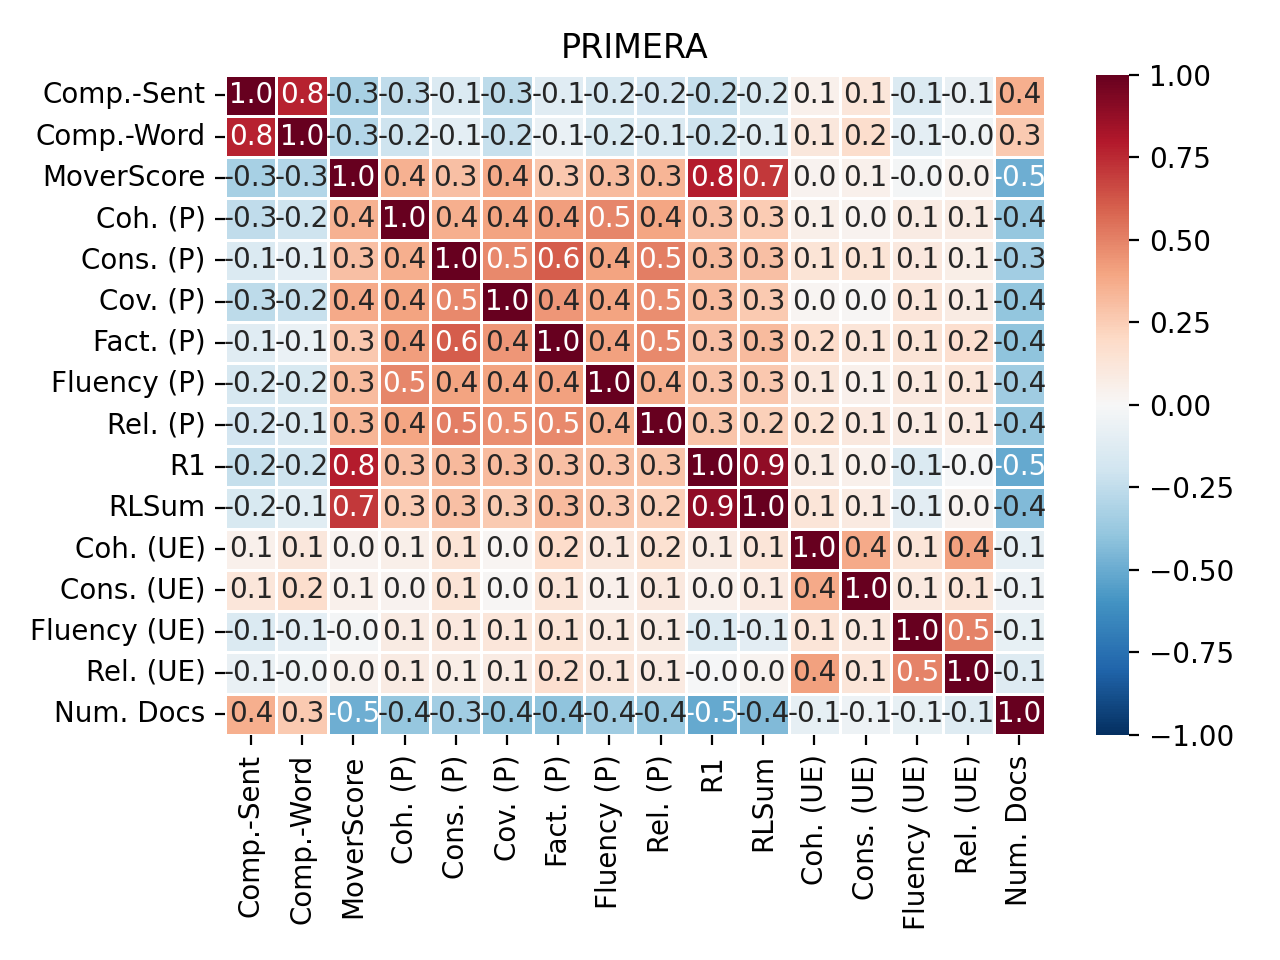

<IPython.core.display.Javascript object>


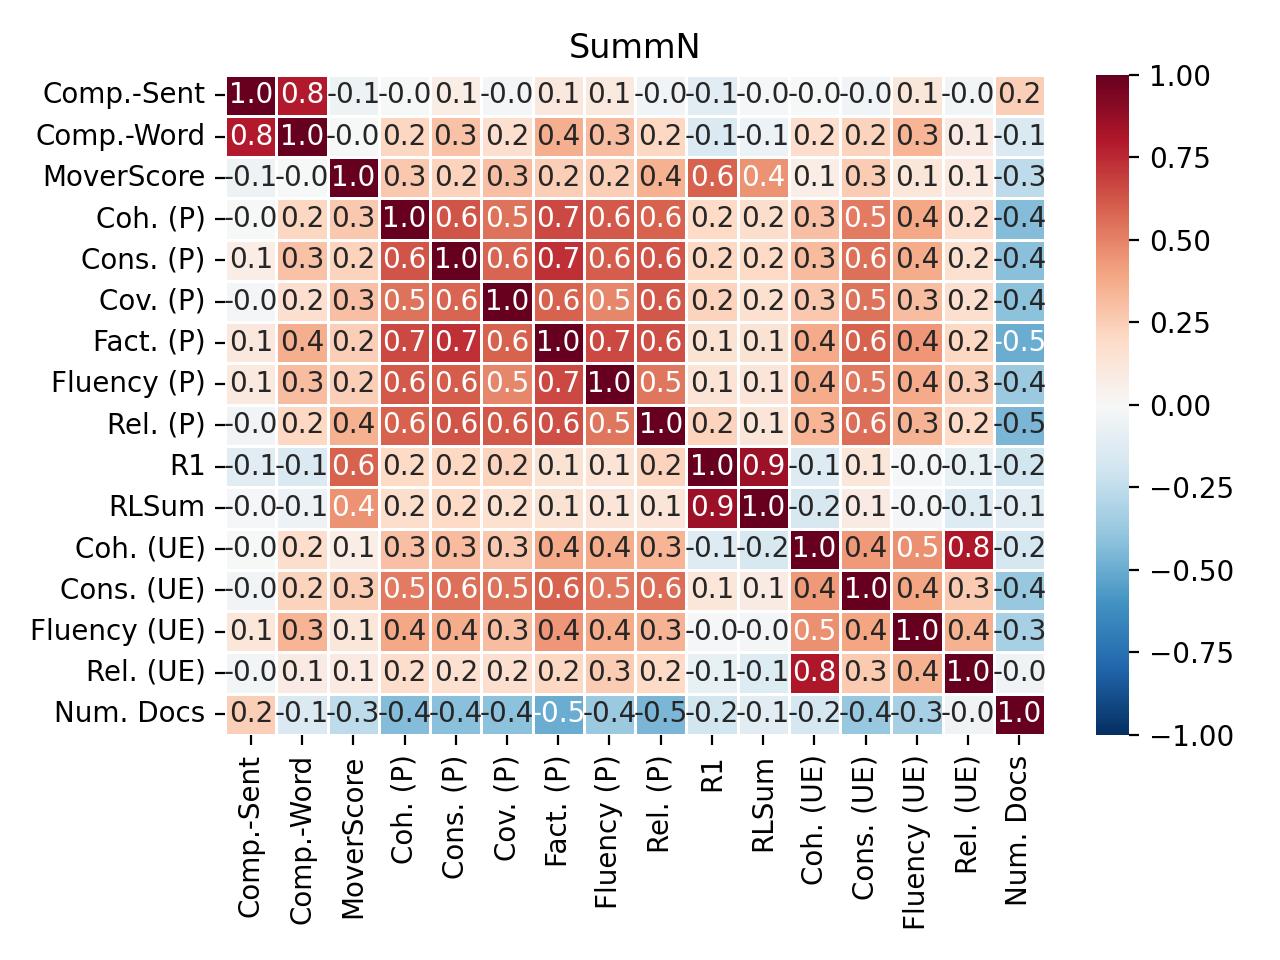

In [12]:
counter = 1
for run, run_df in transfer_df.groupby("model_type"):
    fig = plt.figure(num=counter)
    ax = plt.gca()
    if "ICL" in run:
        run = run.replace("ICL", "Llama 3.1")
    ax.set_title(run)
    corr_df = run_df[correlation_metrics].corr(method='pearson', min_periods=1, numeric_only=False)
    corr_df = corr_df.rename(columns=metric_name_mapping, index=metric_name_mapping)
    sns.heatmap(corr_df, annot=True, fmt=".1f", linewidth=.5, cmap="RdBu_r", ax=ax, center=0.0, vmin=-1, vmax=1)
    counter += 1
    plt.tight_layout()
